# Dynamic structure factor — liquid water

**NJOY**

Compare the reference and three stochastic vibrational spectra using outgoing-energy slices of the dynamic structure factor (DSF). NJOY LEAPR supplies the hydrogen scattering law in MF7. TARA evaluates the DSF for the selected incident energies and angles.

**NCrystal**

Compare the reference and three stochastic vibrational spectra using outgoing-energy slices of the dynamic structure factor (DSF). The NCrystal Liquids plugin supplies the native hydrogen kernel. TARA converts that kernel to a DSF for the selected incident energies and angles.

## 0. Choose the engine

**Required setting**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `ENGINE` | `"ncrystal"` | Select `"njoy"` or `"ncrystal"` for this run. |

After changing the engine, restart the kernel and run all cells.

In [1]:
AVAILABLE_ENGINE = ("njoy", "ncrystal")
AVAILABLE_ENGINE_LABEL = {
    "njoy": "NJOY",
    "ncrystal": "NCrystal"
}

In [2]:
ENGINE = "ncrystal"
if ENGINE not in AVAILABLE_ENGINE:
    raise ValueError('Choose ENGINE = "njoy" or "ncrystal".')
ENGINE_LABEL = AVAILABLE_ENGINE_LABEL[ENGINE]

## 1. Locate TARA

The next cell finds TARA and imports the APIs for the chosen engine.

In [3]:
from pathlib import Path
import os
import shutil
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "core" / "config.py").is_file()
     and (path / "processing" / "pipelines" / "ace_pipeline.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the TARA repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import parallel_execution
from core.config import TaraConfig
from core.data.input_pdos import PhononSpectra
from core.sampler.concrete_samplers import TaraSampler

if ENGINE == "njoy":
    from input_output.leapr.core import LeaprFile
    from input_output.leapr.material_adapter import material_model_from_leapr
elif ENGINE == "ncrystal":
    from input_output.ncrystal.core import NCrystalFile
    from input_output.ncrystal.liquids import load_liquid_ncmat, parse_custom_liquids

## 2. Select the required inputs

| Setting | Example value | What it controls |
| --- | --- | --- |
| `BASE_LEAPR_FILE` | `tests/fixtures/tsl-HinH2O.leapr` | NJOY material template. |
| `BASE_NCMAT_FILE` | `tests/fixtures/liquid_water_295K_illustrative.ncmat` | NCrystal material. |
| `BASE_ENDF_FILE` | `tests/fixtures/n_1-H-001g.jeff` | Neutron evaluation for the NJOY path. Override with `TARA_BASE_ENDF` if needed. |
| `NJOY_EXECUTABLE` | `NJOY_EXEC` or `njoy` on `PATH` | Executable for the NJOY path. |

Edit paths only if your checkout or NJOY installation uses different locations.

NCrystal liquid calculations require the Liquids plugin.

In [4]:
fixtures = PROJECT_ROOT / "tests" / "fixtures"
BASE_ENDF_FILE = Path(os.environ.get("TARA_BASE_ENDF", str(fixtures / "n_1-H-001g.jeff")))
njoy_path = shutil.which(os.environ.get("NJOY_EXEC") or "njoy")
NJOY_EXECUTABLE = Path(njoy_path) if njoy_path else None

if ENGINE == "njoy":
    if not BASE_ENDF_FILE.is_file() or BASE_ENDF_FILE.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty neutron ENDF: {BASE_ENDF_FILE}")
    if NJOY_EXECUTABLE is None:
        raise FileNotFoundError("Set NJOY_EXEC or add njoy to PATH.")

    print("Neutron ENDF:", BASE_ENDF_FILE)
    print("NJOY:", NJOY_EXECUTABLE)

In [5]:
if ENGINE == "njoy":
    BASE_LEAPR_FILE = fixtures / "tsl-HinH2O.leapr"
    if not BASE_LEAPR_FILE.is_file():
        raise FileNotFoundError(f"LEAPR template missing: {BASE_LEAPR_FILE}")
elif ENGINE == "ncrystal":
    BASE_NCMAT_FILE = fixtures / "liquid_water_295K_illustrative.ncmat"
    if not BASE_NCMAT_FILE.is_file():
        raise FileNotFoundError(f"NCMAT template missing: {BASE_NCMAT_FILE}")

## 3. Load the liquid water reference

**Fixed settings for this example**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `TEMPERATURE_K` | `295` | Evaluation temperature in kelvin. |
| `ATOM_LABEL` | `"H"` | Species supplying the reference spectrum. |

In [6]:
TEMPERATURE_K = 295.0
ATOM_LABEL = "H"
print(f"Engine: {ENGINE_LABEL}")
print(f"temperature: {TEMPERATURE_K:g} K")

if ENGINE == "njoy":
    template = LeaprFile.from_file(str(BASE_LEAPR_FILE))
    leapr_template = template

    material = material_model_from_leapr(
        template, state="liquid", temperature=TEMPERATURE_K,
        principal_label=ATOM_LABEL, secondary_label="O",
    )
    if (material.principal.multiplicity != 2 or len(material.secondary) != 1
            or material.secondary[0].multiplicity != 1):
        raise ValueError("Expected the CAB H-in-water LEAPR material.")
    dynamics = material.dynamics
    reference_spectrum = dynamics.continuous
    raw_pdos = reference_spectrum.pdos
    vibrational_weight = dynamics.continuous_weight + sum(
        oscillator.weight for oscillator in dynamics.oscillators
    )
    translation_weight = dynamics.translation_weight
    print(f"LEAPR file: {BASE_LEAPR_FILE}")
elif ENGINE == "ncrystal":
    source_text = load_liquid_ncmat(BASE_NCMAT_FILE)
    liquid_entries = parse_custom_liquids(source_text)
    liquid_settings = next((entry for entry in liquid_entries if entry.atom == ATOM_LABEL), None)
    if liquid_settings is None:
        raise ValueError(f"No custom liquid settings for {ATOM_LABEL!r}.")
    vibrational_weight = liquid_settings.ws
    translation_weight = liquid_settings.wt

    material = NCrystalFile.from_file(str(BASE_NCMAT_FILE))
    raw_pdos = material.pdos_for_atom(ATOM_LABEL)
    reference_spectrum = PhononSpectra(pdos=raw_pdos)
    print(f"NCMAT file: {BASE_NCMAT_FILE}")

print(f"Vibrational weight: {vibrational_weight:g}")
print(f"Translation weight: {translation_weight:g}")

Engine: NCrystal
temperature: 295 K
NCMAT file: /home/aitor/postdoc/tara_preview_V3_5/tests/fixtures/liquid_water_295K_illustrative.ncmat
Vibrational weight: 0.99197
Translation weight: 0.0080324


## 4. Sample the vibrational spectrum

**Required:** The reference material from Section 3 and the two perturbation bounds below. Select a positive sample count for the comparison.

**Required sampling settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `MAX_ENERGY_SHIFT_MEV` | `5.0` | Maximum phonon-energy displacement in meV. |
| `MAX_AMPLITUDE_SHIFT_PCT` | `5.0` | Maximum relative PDOS amplitude change in percent. |
| `N_SAMPLES` | `3` | Number of stochastic samples. The reference is stored separately. |

**NJOY**

The default settings below let the low-energy shoulder and the broad continuum peak vary independently. The zero-energy point stays fixed. The bending and stretching modes are sampled in the same ensemble.

**NCrystal**

The NCMAT liquid settings are retained.

In [7]:
MAX_ENERGY_SHIFT_MEV = 5.0
MAX_AMPLITUDE_SHIFT_PCT = 5.0
N_SAMPLES = 3

**Optional sampling settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `RANDOM_SEED` | `20261014` | Seed for reproducible sampling. |
| `BATCH_SIZE` | `512` | Internal sampling chunk size. |
| `AMPLITUDE_METHOD` | `"fast"` | Method used for the amplitude perturbations. |
| `SPATIAL_METHOD` | `"diffeomorphic"` | Method used to shift the spectrum in energy. |

In [8]:
RANDOM_SEED = 20261014
BATCH_SIZE = 512
AMPLITUDE_METHOD = "fast"
SPATIAL_METHOD = "diffeomorphic"

In [ ]:
# Validate all perturbation bounds and sampling strategies using TaraConfig.
configuration = TaraConfig(
    max_energy_shift_mev=MAX_ENERGY_SHIFT_MEV,
    max_amplitude_shift_pct=MAX_AMPLITUDE_SHIFT_PCT,
    n_samples=N_SAMPLES,
    random_seed=RANDOM_SEED,
)

# Initialize TaraSampler with the selected amplitude and spatial methods.
sampler = TaraSampler(
    config=configuration,
    spectra=reference_spectrum,
    amplitude_method=AMPLITUDE_METHOD,
    spatial_method=SPATIAL_METHOD,
)

# Generate the stochastic ensemble with the configured sampling batch size.
ensemble = sampler.generate_ensemble(batch_size=BATCH_SIZE)
if ensemble.reference is None or len(ensemble) != N_SAMPLES:
    raise RuntimeError("Expected the reference and all requested samples.")
print(f"Prepared one reference and {len(ensemble)} stochastic spectra.")

Prepared one reference and 3 stochastic spectra.


## 5. Configure the Analyzer and request the dynamic structure factor

**NJOY**

**Required:** The material from Section 3 and the ensemble from Section 4. Pass the original CAB LEAPR file so the runner can export sampled modes on the native representation.

**NCrystal**

**Required:** The material from Section 3 and the ensemble from Section 4. Processing builds the temporary liquid capture adapter automatically.

In [10]:
import numpy as np
from analyzer.ensemble_analyzer import EnsembleAnalyzer

if ENGINE == "njoy":
    from endf_parserpy import EndfParserPy
    from scipy.constants import physical_constants
    from analyzer.parsers.njoy_parser import NjoyParser
    from analyzer.runners.njoy_runner import NjoyRunner

    base_header = EndfParserPy().parsefile(str(BASE_ENDF_FILE), include=[1])[1][451]
    if int(round(float(base_header["ZA"]))) != 1001:
        raise ValueError("Expected base neutron evaluation ZA=1001.")
    MASS_AMU = float(template.principal_scatterer["awr"]) * physical_constants["neutron mass in u"][0]
elif ENGINE == "ncrystal":
    from analyzer.parsers.ncrystal_parser import NCrystalParser
    from analyzer.runners.ncrystal_runner import NCrystalRunner

In [11]:
if ENGINE == "njoy":
    runner = NjoyRunner(
        njoy_exec=str(NJOY_EXECUTABLE),
        base_endf_file=str(BASE_ENDF_FILE),
        base_leapr_file=str(BASE_LEAPR_FILE),
        temperature=TEMPERATURE_K,
        mass_amu=MASS_AMU,
    )
    parser = NjoyParser()
elif ENGINE == "ncrystal":
    runner = NCrystalRunner(
        base_ncmat_file=str(BASE_NCMAT_FILE),
        temperature=TEMPERATURE_K,
    )
    parser = NCrystalParser()

In [12]:
analyzer = EnsembleAnalyzer(ensemble=ensemble, runner=runner, parser=parser)

**Required observable settings**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `INCIDENT_ENERGIES` | `[0.0253, 0.05, 0.1]` eV | Incident energies evaluated for the reference and samples. |
| `THETA_GRID` | 0°–180° in 1° steps | Scattering angles evaluated by the Analyzer. |

The Analyzer uses the backend’s signed scattering law to evaluate the DSF on its kinematic grid. Each result is stored by incident energy, with scattering cosine on rows and outgoing neutron energy in eV on columns.

**NCrystal**

Keep each incident energy within the captured liquid kernel’s supported range.

In [13]:
INCIDENT_ENERGIES = np.array([0.0253, 0.05, 0.1], dtype=float)
THETA_GRID = np.arange(181, dtype=float)

parser_kwargs = dict(
    calc_dsf=True,
    ein_arr=INCIDENT_ENERGIES,
    theta=THETA_GRID,
    calc_xs_total=False,
    calc_xs_inelastic=False,
    calc_xs_elastic=False,
    calc_xs_absorption=False,
)

## 6. Run the Analyzer

**NJOY**

**Required:** The Analyzer and observable settings from Section 5. Evaluate the reference separately so Section 7 can overlay it with the stochastic DSF profiles.

**Optional execution and THERMR settings:**

| Setting | Example value | What it controls |
| --- | --- | --- |
| `export_full_spectra` | `False` | Export the native continuum and sampled discrete modes. Set to `True` for a complete `ND=0` table. |
| `RUN_PARALLEL` | `False` | Run sequentially or request concurrent processing. |
| `thermr_emax` | `5.0` | Upper THERMR processing energy in eV. |
| `thermr_tol` | `0.05` | THERMR interpolation tolerance. |
| `thermr_nbin` | `16` | THERMR angular bin count. |

**NCrystal**

**Required:** The Analyzer and observable settings from Section 5 and the atom label from Section 3. Evaluate the reference separately so Section 7 can overlay it with the stochastic DSF profiles.

**Optional setting:** `RUN_PARALLEL` controls concurrent execution.

In [14]:
RUN_PARALLEL = False

if ENGINE == "njoy":
    RUNNER_OPTIONS = {
        "export_full_spectra": False,
        "thermr_emax": 5.0,
        "thermr_tol": 0.05,
        "thermr_nbin": 16,
    }
elif ENGINE == "ncrystal":
    RUNNER_OPTIONS = {"atom_label": ATOM_LABEL}

In [ ]:
# Compute the ensemble results using the configured analyzer.
analyzer.compute(
    parallel=RUN_PARALLEL,
    runner_kwargs=RUNNER_OPTIONS,
    parser_kwargs=parser_kwargs,
    compute_reference=True,
)

if analyzer.reference_result is None or len(analyzer.raw_results) != len(ensemble):
    raise RuntimeError("The Analyzer did not return the expected reference and samples.")
for result in (analyzer.reference_result, *analyzer.raw_results):
    tables = result.diff.dynamic_structure_factor or {}
    if any(energy not in tables or tables[energy].empty for energy in INCIDENT_ENERGIES):
        raise RuntimeError(f"Missing DSF data for result {result.sample_index}.")

print(f"Computed DSF tables at {len(INCIDENT_ENERGIES)} energies for "
      f"the reference and {len(analyzer.raw_results)} samples.")

Computed DSF tables at 3 energies for the reference and 3 samples.


## 7. Plot dynamic structure factor slices

**Required:** The reference and sample results from Section 6. Select an incident energy and scattering angle to view DSF versus outgoing neutron energy. The water VDOS is split into low-energy, bending, and stretching panels.

**Optional display setting:** `ENERGY_THRESHOLD` sets the relative intensity used to choose the outgoing-energy display window. The sliders read the stored results. If `ipywidgets` is unavailable, the notebook renders the initial slice.

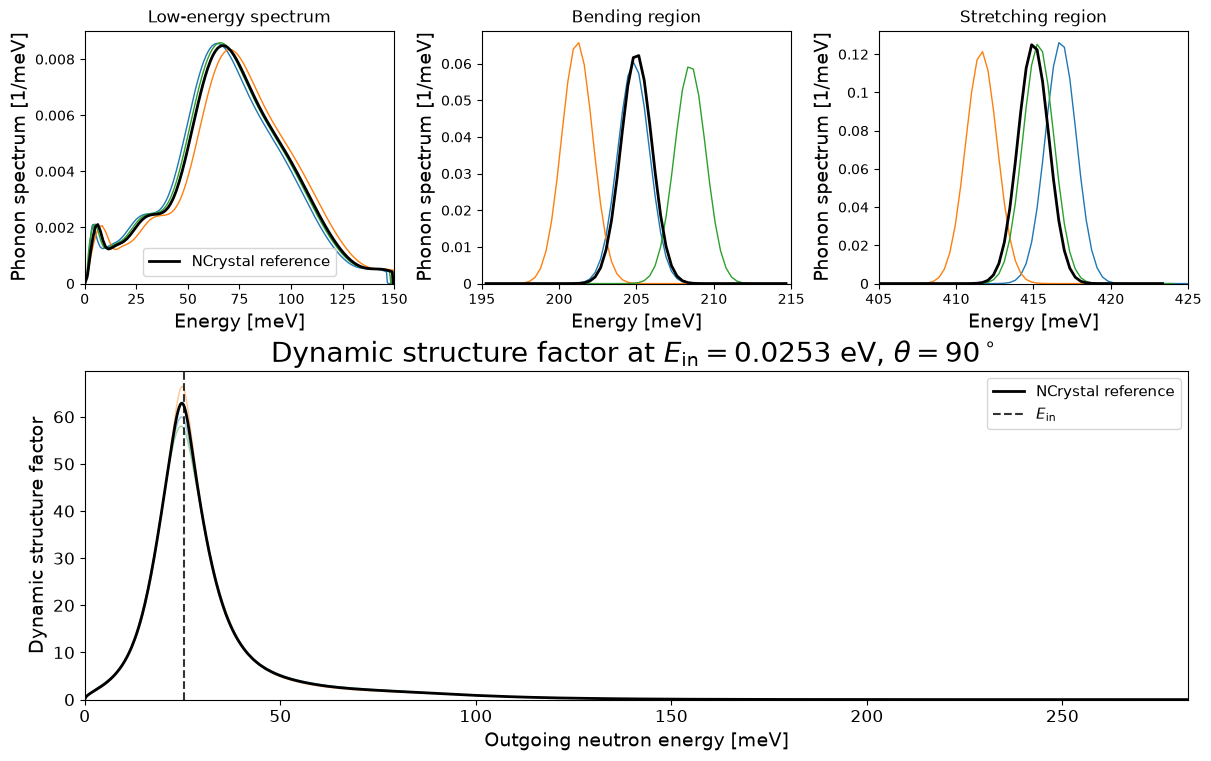

In [16]:
import io

import matplotlib.pyplot as plt
from IPython.display import display

REF_LABEL = f"{ENGINE_LABEL} reference"
ENERGY_THRESHOLD = 1e-5
incident_energies = tuple(float(energy) for energy in INCIDENT_ENERGIES)
angles = tuple(float(angle) for angle in THETA_GRID)
initial_angle = min(angles, key=lambda angle: abs(angle - 90.0))

from notebooks.tara_plotting import plot_PDOS, plot_dsf_energy_slice


def dsf_figure(incident_energy, angle):
    """Show water's three VDOS bands and the selected DSF slice."""
    fig = plt.figure(figsize=(12, 7.5), layout="constrained")
    grid = fig.add_gridspec(2, 3, height_ratios=(1, 1.3))
    for column, (title, lower, upper) in enumerate((
        ("Low-energy spectrum", 0.0, 0.150),
        ("Bending region", 0.195, 0.215),
        ("Stretching region", 0.405, 0.425),
    )):
        axis = fig.add_subplot(grid[0, column])
        spectra = [sample.pdos.loc[lower:upper] for sample in ensemble]
        reference = ensemble.reference.pdos.loc[lower:upper]
        plot_PDOS(axis, spectra, reference, title=title,
                  ref_label=REF_LABEL, title_fontsize=12)
        axis.set_xlim(lower, upper)
        if column > 0:
            axis.get_legend().remove()

    result_axis = fig.add_subplot(grid[1, :])
    plot_dsf_energy_slice(
        result_axis, analyzer, incident_energy, angle,
        ref_label=REF_LABEL, energy_threshold=ENERGY_THRESHOLD,
    )
    return fig

try:
    import ipywidgets as widgets
except ImportError:
    figure = dsf_figure(incident_energies[0], initial_angle)
    display(figure)
    plt.close(figure)
else:
    energy_selector = widgets.SelectionSlider(
        options=[(f"{energy:g} eV", energy) for energy in incident_energies],
        description="Incident energy",
        continuous_update=False,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="min(650px, 100%)"),
    )
    angle_selector = widgets.SelectionSlider(
        options=[(f"{angle:g}°", angle) for angle in angles],
        value=initial_angle,
        description="Scattering angle",
        continuous_update=False,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="min(650px, 100%)"),
    )
    plot_image = widgets.Image(format="png", layout=widgets.Layout(width="100%"))

    def update_dsf(change=None):
        """Redraw the selected profile using stored Analyzer results."""
        figure = dsf_figure(energy_selector.value, angle_selector.value)
        try:
            with io.BytesIO() as buffer:
                figure.savefig(buffer, format="png", dpi=120)
                plot_image.value = buffer.getvalue()
        finally:
            plt.close(figure)

    energy_selector.observe(update_dsf, names="value")
    angle_selector.observe(update_dsf, names="value")
    update_dsf()
    display(widgets.VBox([energy_selector, angle_selector, plot_image]))